# IT3212 – Assignment 3 – Tasks 5 & 6: Classification and Comparison

This notebook builds on **Task 4 (Feature Selection)**. Task 5 implements and justifies three classification algorithms using the same 18 selected input features and the existing training/validation split.

**Models:** Decision Tree, Naive Bayes and a Neural Network (MLP).

**Target:** `smoking` (`0` = never smoked, `1` = current or former smoker).

**Inputs:** `../data/assignment3/task4_train.csv`, `task4_val.csv`, and `task4_metadata.json`.

The test set is intentionally not loaded at this stage. It is reserved for the final evaluation after model decisions have been made.

## Task 5 – Implement and justify three algorithms

### Imports and data loading

In [3]:
import json
import time
from pathlib import Path

import joblib
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_DIR = Path("../data/assignment3")
RANDOM_STATE = 42

with open(DATA_DIR / "task4_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

TARGET = metadata["target"]
FEATURES = metadata["selected_features"]
SCALE_COLS = metadata["scaling"]["columns"]

train_df = pd.read_csv(DATA_DIR / "task4_train.csv")
val_df = pd.read_csv(DATA_DIR / "task4_val.csv")

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_val = val_df[FEATURES]
y_val = val_df[TARGET]

assert len(FEATURES) == 18, "Expected 18 selected features from Task 4."
assert all(c in X_train.columns for c in SCALE_COLS)
assert not X_train.isna().any().any() and not X_val.isna().any().any()
assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}

print(f"Train: {X_train.shape[0]:,} rows, {X_train.shape[1]} features")
print(f"Val:   {X_val.shape[0]:,} rows, {X_val.shape[1]} features")
print(f"Smoking class share in train: {y_train.mean():.3f}")
print(f"Columns to scale for MLP: {len(SCALE_COLS)}")
print(f"Selected features: {FEATURES}")

Train: 787,625 rows, 18 features
Val:   98,453 rows, 18 features
Smoking class share in train: 0.392
Columns to scale for MLP: 17
Selected features: ['sex', 'height', 'hemoglobin', 'weight', 'gamma_GTP', 'serum_creatinine', 'waistline', 'TG_HDL_ratio', 'triglyceride', 'BMI', 'SGOT_ALT', 'AST_ALT_ratio', 'HDL_chole', 'waist_height_ratio', 'cholesterol_ratio', 'LDL_HDL_ratio', 'age', 'SGOT_AST']


### Decision Tree


### Hyperparameter comparison

Decision Tree depth comparison:


,max_depth,actual_depth,train_F1,val_F1,train_accuracy,val_accuracy,fit_seconds
0,3,3,0.7779,0.7776,0.8068,0.8063,2.3657
1,5,5,0.7850,0.7856,0.8094,0.8096,3.8582
2,8,8,0.7849,0.7841,0.8110,0.8101,5.7511
3,12,12,0.7875,0.7792,0.8153,0.8081,8.5570
4,16,16,0.7894,0.7681,0.8205,0.8022,10.8329


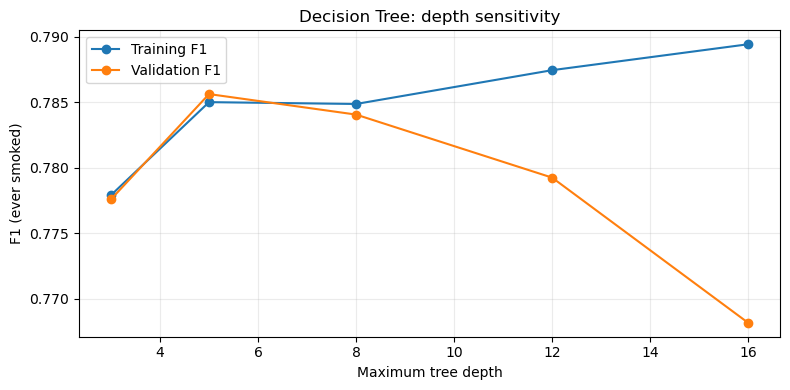

Selected max_depth=5 (validation F1=0.7856)


In [4]:
import matplotlib.pyplot as plt

# Decision Tree sensitivity to maximum depth.
# Compare candidates before fitting the final Decision Tree.
tree_trials = []
for depth in [3, 5, 8, 12, 16]:
    trial = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE
    )
    start = time.perf_counter()
    trial.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    tree_trials.append({
        "max_depth": depth,
        "actual_depth": trial.get_depth(),
        "train_F1": f1_score(y_train, trial.predict(X_train)),
        "val_F1": f1_score(y_val, trial.predict(X_val)),
        "train_accuracy": accuracy_score(y_train, trial.predict(X_train)),
        "val_accuracy": accuracy_score(y_val, trial.predict(X_val)),
        "fit_seconds": elapsed,
    })

tree_tuning_df = pd.DataFrame(tree_trials)
print("Decision Tree depth comparison:")
display(tree_tuning_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tree_tuning_df["max_depth"], tree_tuning_df["train_F1"], marker="o", label="Training F1")
ax.plot(tree_tuning_df["max_depth"], tree_tuning_df["val_F1"], marker="o", label="Validation F1")
ax.set(xlabel="Maximum tree depth", ylabel="F1 (ever smoked)", title="Decision Tree: depth sensitivity")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
# Select by external validation F1; for exact ties prefer the shallower tree.
best_tree_row = tree_tuning_df.sort_values(["val_F1", "max_depth"], ascending=[False, True]).iloc[0]
best_tree_depth = int(best_tree_row["max_depth"])
print(f"Selected max_depth={best_tree_depth} (validation F1={best_tree_row['val_F1']:.4f})")


### Final model

In [5]:
decision_tree = DecisionTreeClassifier(
    max_depth=best_tree_depth,
    min_samples_leaf=50,
    random_state=RANDOM_STATE
)

start = time.perf_counter()
decision_tree.fit(X_train, y_train)
tree_train_time = time.perf_counter() - start

print(f"Decision Tree trained in {tree_train_time:.2f} seconds")
print("Tree depth:", decision_tree.get_depth())
print("Number of leaf nodes:", decision_tree.get_n_leaves())


Decision Tree trained in 3.68 seconds
Tree depth: 5
Number of leaf nodes: 32


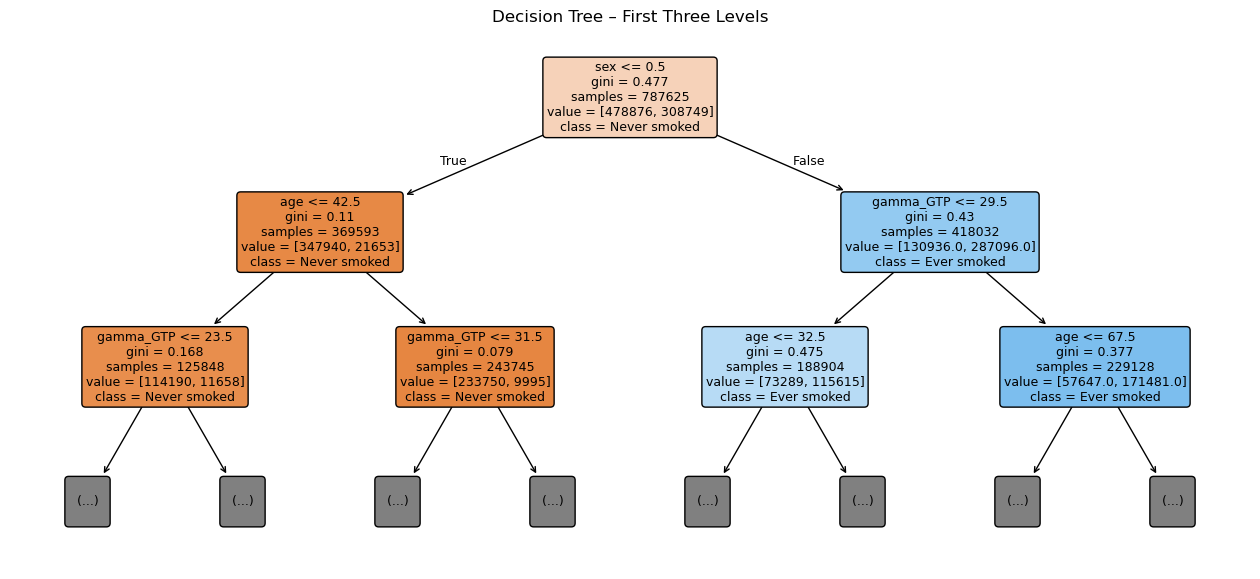

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 7))

plot_tree(
    decision_tree,
    feature_names=X_train.columns,
    class_names=["Never smoked", "Ever smoked"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Decision Tree – First Three Levels")
plt.show()

### Naive Bayes

In [7]:
naive_bayes = GaussianNB()

start = time.perf_counter()
naive_bayes.fit(X_train, y_train)
nb_train_time = time.perf_counter() - start

print(f"Gaussian Naive Bayes trained in {nb_train_time:.2f} seconds")


Gaussian Naive Bayes trained in 0.25 seconds


#### Class-conditional feature distributions

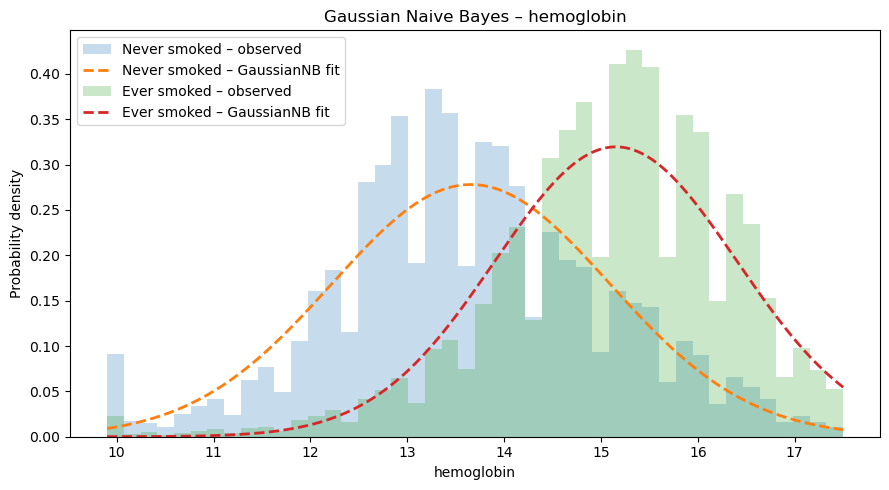

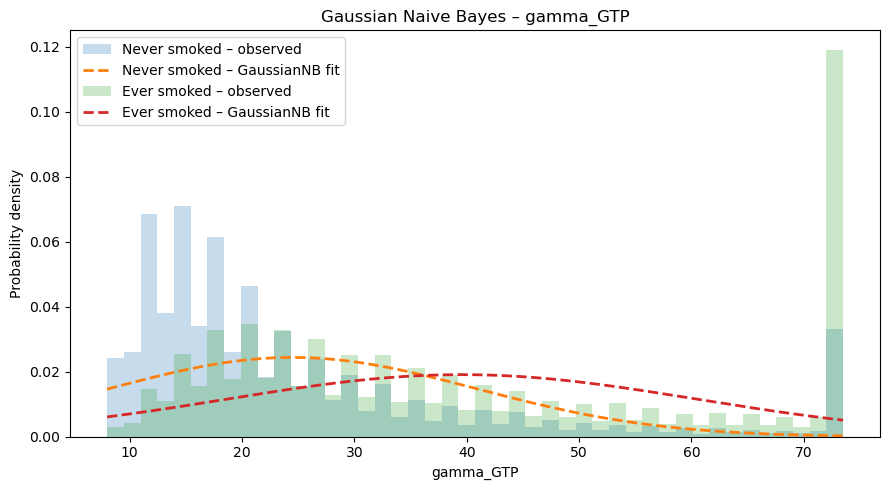

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

class_labels = {0: "Never smoked", 1: "Ever smoked"}

for feature in ["hemoglobin", "gamma_GTP"]:
    assert feature in FEATURES, f"{feature} is not among the selected features"
    feature_idx = FEATURES.index(feature)

    low, high = X_train[feature].quantile([0.01, 0.99])
    x_values = np.linspace(low, high, 400)
    bins = np.linspace(low, high, 45)

    plt.figure(figsize=(9, 5))

    for class_idx, class_label in enumerate(naive_bayes.classes_):
        values = X_train.loc[y_train == class_label, feature]

        # Use a representative sample to make plotting faster.
        values = values.sample(n=min(20_000, len(values)), random_state=RANDOM_STATE)

        plt.hist(
            values, bins=bins, density=True, alpha=0.25,
            label=f"{class_labels[class_label]} – observed"
        )

        mean = naive_bayes.theta_[class_idx, feature_idx]
        std = np.sqrt(naive_bayes.var_[class_idx, feature_idx])
        plt.plot(
            x_values, norm.pdf(x_values, loc=mean, scale=std),
            linestyle="--",
            linewidth=2,
            label=f"{class_labels[class_label]} – GaussianNB fit"
        )

    plt.xlabel(feature)
    plt.ylabel("Probability density")
    plt.title(f"Gaussian Naive Bayes – {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Neural Network (MLP)

### Architecture comparison

In [9]:
# Compare architectures before fitting the final MLP.
mlp_trials = []
for layers in [(16,), (32,), (64,), (32, 16)]:
    trial_mlp = Pipeline([
        ("preprocessor", ColumnTransformer(
            transformers=[("continuous", StandardScaler(), SCALE_COLS)],
            remainder="passthrough"
        )),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=layers,
            activation="relu", solver="adam", batch_size=512,
            max_iter=60, early_stopping=True, n_iter_no_change=8,
            random_state=RANDOM_STATE,
        )),
    ])
    start = time.perf_counter()
    trial_mlp.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    mlp_trials.append({
        "hidden_layers": str(layers),
        "train_F1": f1_score(y_train, trial_mlp.predict(X_train)),
        "val_F1": f1_score(y_val, trial_mlp.predict(X_val)),
        "val_ROC_AUC": roc_auc_score(y_val, trial_mlp.predict_proba(X_val)[:, 1]),
        "epochs": trial_mlp.named_steps["classifier"].n_iter_,
        "fit_seconds": elapsed,
    })

mlp_tuning_df = pd.DataFrame(mlp_trials)
print("MLP architecture comparison (exploratory):")
display(mlp_tuning_df.round(4))


MLP architecture comparison (exploratory):


,hidden_layers,train_F1,val_F1,val_ROC_AUC,epochs,fit_seconds
0,"(16,)",0.7855,0.7855,0.8793,13,8.6246
1,"(32,)",0.7849,0.7850,0.8801,16,12.3390
2,"(64,)",0.7861,0.7856,0.8804,23,31.1944
3,"(32, 16)",0.7862,0.7857,0.8803,13,13.6156


In [10]:
# Select the simplest architecture with comparable validation performance.
# The F1 difference between (16,) and the best architecture is only 0.0002.
best_mlp_layers = (16,)

selected_row = mlp_tuning_df[
    mlp_tuning_df["hidden_layers"] == str(best_mlp_layers)
].iloc[0]

print(
    f"Selected hidden_layer_sizes={best_mlp_layers} "
    f"(validation F1={selected_row['val_F1']:.4f})"
)

Selected hidden_layer_sizes=(16,) (validation F1=0.7855)


### Final model

In [11]:
preprocessor = ColumnTransformer(
    transformers=[("continuous", StandardScaler(), SCALE_COLS)],
    remainder="passthrough"
)

mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=best_mlp_layers,
        activation="relu",
        solver="adam",
        batch_size=512,
        max_iter=60,
        early_stopping=True,
        n_iter_no_change=8,
        random_state=RANDOM_STATE,
    ))
])

start = time.perf_counter()
mlp.fit(X_train, y_train)
mlp_train_time = time.perf_counter() - start

print(f"Neural Network trained in {mlp_train_time:.2f} seconds")
print("Epochs completed:", mlp.named_steps["classifier"].n_iter_)


Neural Network trained in 8.65 seconds
Epochs completed: 13


#### Training loss

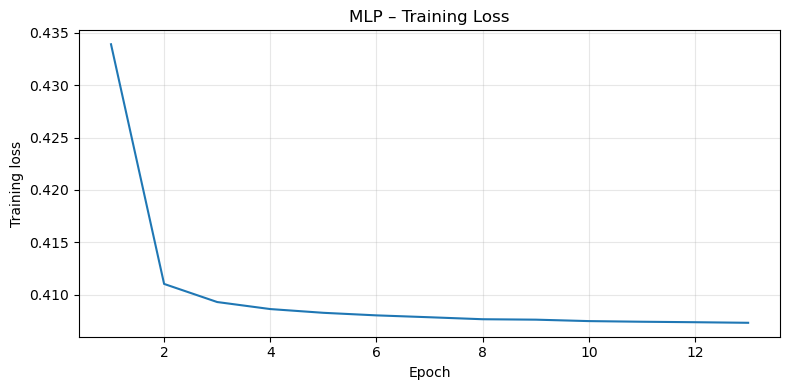

In [12]:
import matplotlib.pyplot as plt

training_loss = mlp.named_steps["classifier"].loss_curve_
epochs = range(1, len(training_loss) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, training_loss)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("MLP – Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Internal validation accuracy

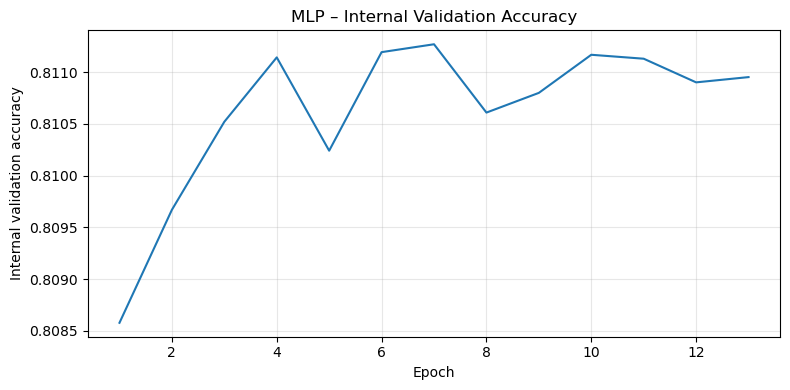

In [13]:
validation_scores = mlp.named_steps["classifier"].validation_scores_

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(validation_scores) + 1), validation_scores)
plt.xlabel("Epoch")
plt.ylabel("Internal validation accuracy")
plt.title("MLP – Internal Validation Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Training vs. validation: generalization check

In [14]:
models = {
    "Decision Tree": decision_tree,
    "Gaussian Naive Bayes": naive_bayes,
    "Neural Network (MLP)": mlp,
}
training_times = {
    "Decision Tree": tree_train_time,
    "Gaussian Naive Bayes": nb_train_time,
    "Neural Network (MLP)": mlp_train_time,
}

generalization_rows = []
for name, model in models.items():
    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)
    train_f1 = f1_score(y_train, pred_train)
    val_f1 = f1_score(y_val, pred_val)
    generalization_rows.append({
        "Model": name,
        "Training accuracy": accuracy_score(y_train, pred_train),
        "Validation accuracy": accuracy_score(y_val, pred_val),
        "Training F1": train_f1,
        "Validation F1": val_f1,
        "F1 gap (train - val)": train_f1 - val_f1,
    })

generalization_df = pd.DataFrame(generalization_rows).set_index("Model")
display(generalization_df.round(4))


,Training accuracy,Validation accuracy,Training F1,Validation F1,F1 gap (train - val)
Model,,,,,
Decision Tree,0.8094,0.8096,0.7850,0.7856,-0.0006
Gaussian Naive Bayes,0.7844,0.7852,0.7449,0.7460,-0.0011
Neural Network (MLP),0.8111,0.8110,0.7855,0.7855,-0.0000


## Task 6 – Test performance comparison

In [15]:
# Use the same selected features and column order as during training.
test_df = pd.read_csv(DATA_DIR / "task4_test.csv")
assert all(column in test_df.columns for column in FEATURES + [TARGET])
X_test = test_df[FEATURES]
y_test = test_df[TARGET]
assert not X_test.isna().any().any()
assert set(y_test.unique()) == {0, 1}

# Models remain unchanged; do not call fit() or fit_transform() here.
rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Training time (s)": training_times[name],
    })
    print(f"\n--- {name}: held-out test ---")
    print(classification_report(
        y_test, y_pred,
        target_names=["Never smoked", "Ever smoked"],
        digits=4, zero_division=0
    ))

results_df = pd.DataFrame(rows).set_index("Model")
print("\nHeld-out test comparison:")
display(results_df.round(4))



--- Decision Tree: held-out test ---
              precision    recall  f1-score   support

Never smoked     0.9135    0.7623    0.8311     59860
 Ever smoked     0.7067    0.8881    0.7870     38594

    accuracy                         0.8116     98454
   macro avg     0.8101    0.8252    0.8091     98454
weighted avg     0.8324    0.8116    0.8138     98454


--- Gaussian Naive Bayes: held-out test ---
              precision    recall  f1-score   support

Never smoked     0.8602    0.7767    0.8163     59860
 Ever smoked     0.6990    0.8042    0.7479     38594

    accuracy                         0.7875     98454
   macro avg     0.7796    0.7904    0.7821     98454
weighted avg     0.7970    0.7875    0.7895     98454


--- Neural Network (MLP): held-out test ---
              precision    recall  f1-score   support

Never smoked     0.9096    0.7706    0.8344     59860
 Ever smoked     0.7124    0.8811    0.7878     38594

    accuracy                         0.8140     98454


,Accuracy,F1,ROC-AUC,Training time (s)
Model,,,,
Decision Tree,0.8116,0.7870,0.8719,3.6831
Gaussian Naive Bayes,0.7875,0.7479,0.8495,0.2455
Neural Network (MLP),0.8140,0.7878,0.8813,8.6497


### Class-wise precision, recall and F1 on the test set

In [16]:
from sklearn.metrics import precision_recall_fscore_support

classwise_rows = []
class_names = {0: "Never smoked", 1: "Ever smoked"}
for name, model in models.items():
    precision, recall, f1_values, support = precision_recall_fscore_support(
        y_test, model.predict(X_test), labels=[0, 1], zero_division=0
    )
    for index, label in enumerate([0, 1]):
        classwise_rows.append({
            "Model": name,
            "Class": class_names[label],
            "Precision": precision[index],
            "Recall": recall[index],
            "F1": f1_values[index],
            "Support": support[index],
        })
classwise_df = pd.DataFrame(classwise_rows)
display(classwise_df.round(4))


,Model,Class,Precision,Recall,F1,Support
0,Decision Tree,Never smoked,0.9135,0.7623,0.8311,59860
1,Decision Tree,Ever smoked,0.7067,0.8881,0.7870,38594
2,Gaussian Naive Bayes,Never smoked,0.8602,0.7767,0.8163,59860
3,Gaussian Naive Bayes,Ever smoked,0.6990,0.8042,0.7479,38594
4,Neural Network (MLP),Never smoked,0.9096,0.7706,0.8344,59860
5,Neural Network (MLP),Ever smoked,0.7124,0.8811,0.7878,38594


### Test-set comparison plot

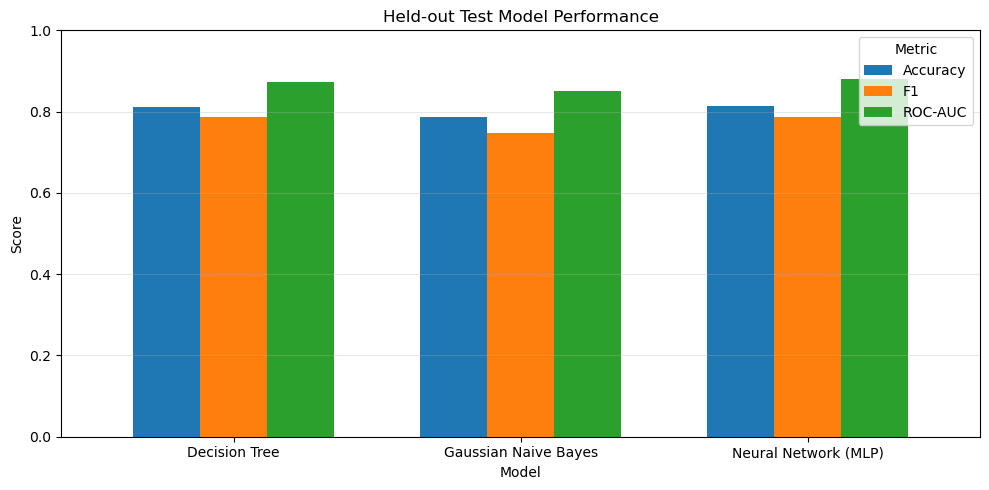

In [17]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "F1", "ROC-AUC"]
ax = results_df[metrics].plot(kind="bar", figsize=(10, 5), width=0.7)
ax.set(title="Held-out Test Model Performance", ylabel="Score", xlabel="Model", ylim=(0, 1))
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Test-set confusion matrices and ROC curves

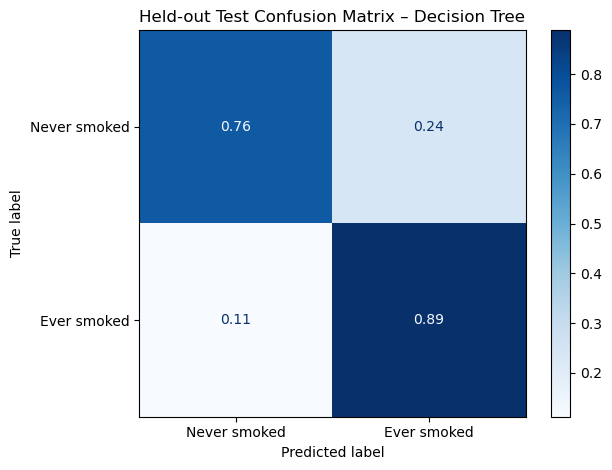

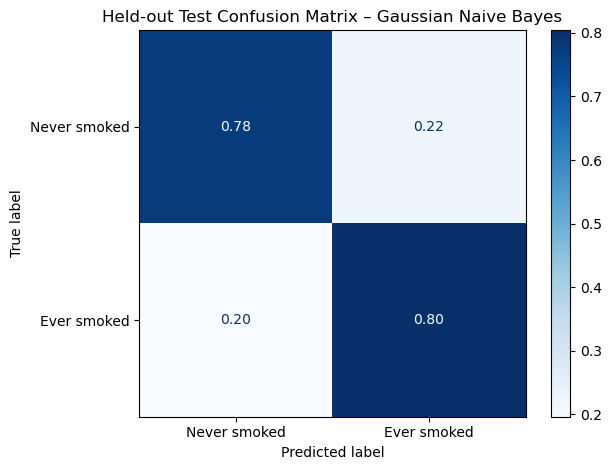

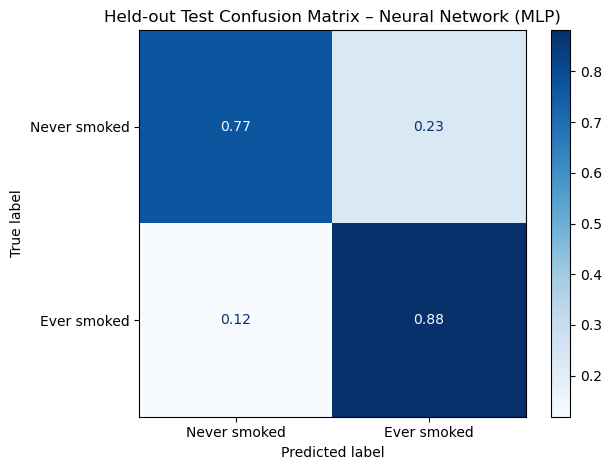

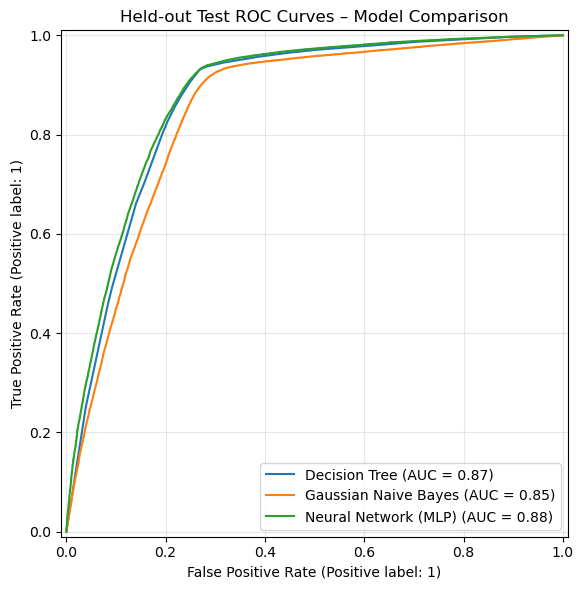

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test),
        display_labels=["Never smoked", "Ever smoked"],
        normalize="true", values_format=".2f", cmap="Blues"
    )
    plt.title(f"Held-out Test Confusion Matrix – {name}")
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Held-out Test ROC Curves – Model Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Save fitted models and evaluation scores

Save the selected estimators, the *development-only* generalization table, and the final test scores for use in later tasks. Do not use test scores to select or adjust models.

In [19]:
MODEL_DIR = DATA_DIR / "task5_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

file_names = {
    "Decision Tree": "decision_tree.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "Neural Network (MLP)": "mlp.joblib",
}
for name, model in models.items():
    joblib.dump(model, MODEL_DIR / file_names[name])

generalization_df.to_csv(DATA_DIR / "task5_train_validation_results.csv")
results_df.to_csv(DATA_DIR / "task5_test_results.csv")
classwise_df.to_csv(DATA_DIR / "task5_test_classwise_results.csv", index=False)
print("Saved fitted models, training/validation diagnostics, and final test scores.")


Saved fitted models, training/validation diagnostics, and final test scores.
